# Codveda Data Science Task Portfolio

This notebook implements six selected tasks from the supplied Codveda Data Science Task List using the supplied datasets.

**Selected tasks**
- Level 1: Data Cleaning & Preprocessing; Exploratory Data Analysis (EDA)
- Level 2: Predictive Modeling (Regression); Classification
- Level 3: NLP Text Classification; Neural Networks

**Important methodological notes**
- The telecom churn files are used as the supplied 80/20 train/test split.
- The housing CSV has no header; standard Boston Housing field names are assigned by column order. The race-derived `B` variable is excluded from modeling as a responsible-feature choice.
- The sentiment dataset contains many emotion labels. A documented rule-based mapping groups them into Positive, Negative, and Neutral for the text-classification task. This is a derived target, not an original three-class label.
- IQR outliers are flagged and reviewed, not automatically deleted, because high usage values may be legitimate observations.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.utils import resample
from sklearn.base import clone

cwd = Path.cwd()
if (cwd / "data" / "raw").exists():
    ROOT = cwd
elif (cwd.parent / "data" / "raw").exists():
    ROOT = cwd.parent
else:
    ROOT = cwd
RAW = ROOT / "data" / "raw" / "Data Set For Task"
OUT = ROOT / "reports"
(OUT / "charts").mkdir(parents=True, exist_ok=True)

sent_raw = pd.read_csv(RAW / "3) Sentiment dataset.csv")
churn_train = pd.read_csv(RAW / "Churn Prdiction Data" / "churn-bigml-80.csv")
churn_test = pd.read_csv(RAW / "Churn Prdiction Data" / "churn-bigml-20.csv")
housing_raw = pd.read_csv(RAW / "4) house Prediction Data Set.csv", sep=r"\s+", header=None)


## Level 1 — Task 1: Data Cleaning and Preprocessing

The churn dataset is checked for missing values, duplicate records, inconsistent text spacing, and IQR-based outliers. Plausible outliers are retained rather than removed automatically.

In [2]:
churn = pd.concat([churn_train.assign(Split="Train"), churn_test.assign(Split="Test")], ignore_index=True)
for col in churn.select_dtypes(include="object").columns:
    churn[col] = churn[col].astype(str).str.strip()
churn["Churn"] = churn["Churn"].astype(bool).astype(int)

quality = {
    "rows": len(churn),
    "columns": churn.shape[1],
    "missing_cells": int(churn.drop(columns=["Split"]).isna().sum().sum()),
    "duplicate_records": int(churn.drop(columns=["Split"]).duplicated().sum())
}
outlier_counts = {}
for col in churn.select_dtypes(include=np.number).columns:
    q1, q3 = churn[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_counts[col] = int(((churn[col] < q1 - 1.5*iqr) | (churn[col] > q3 + 1.5*iqr)).sum())
quality, sorted(outlier_counts.items(), key=lambda x: x[1], reverse=True)[:8]


({'rows': 3333, 'columns': 21, 'missing_cells': 0, 'duplicate_records': 0},
 [('Churn', 483),
  ('Customer service calls', 267),
  ('Total intl calls', 78),
  ('Total intl charge', 49),
  ('Total intl minutes', 46),
  ('Total night minutes', 30),
  ('Total night charge', 30),
  ('Total day minutes', 25)])

## Level 1 — Task 2: Exploratory Data Analysis

EDA focuses on overall churn rate, international-plan status, customer-service calls, and daily usage minutes.

Overall churn rate: 14.49%
Churn by international plan: {'No': 11.5, 'Yes': 42.41}
Churn by 4+ customer service calls: {False: 11.25, True: 51.69}
Average day minutes by churn status: {0: 175.18, 1: 206.91}


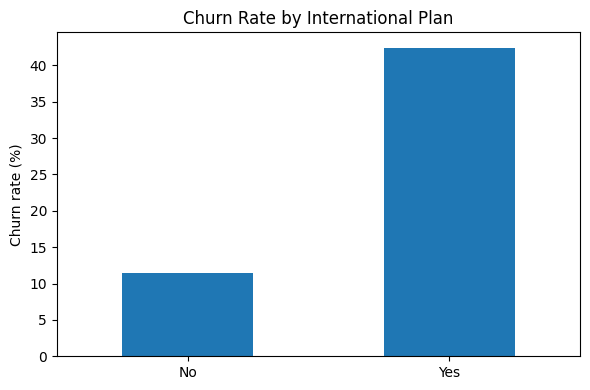

In [3]:
overall_churn_rate = churn["Churn"].mean()
intl_churn = churn.groupby("International plan")["Churn"].mean()
service_flag = churn.assign(FourPlusCalls=churn["Customer service calls"] >= 4).groupby("FourPlusCalls")["Churn"].mean()
day_minutes = churn.groupby("Churn")["Total day minutes"].mean()

print(f"Overall churn rate: {overall_churn_rate:.2%}")
print("Churn by international plan:", (intl_churn*100).round(2).to_dict())
print("Churn by 4+ customer service calls:", (service_flag*100).round(2).to_dict())
print("Average day minutes by churn status:", day_minutes.round(2).to_dict())

fig, ax = plt.subplots(figsize=(6,4))
(churn.groupby("International plan")["Churn"].mean()*100).reindex(["No","Yes"]).plot(kind="bar", ax=ax)
ax.set_title("Churn Rate by International Plan")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


## Level 2 — Task 1: Predictive Modeling (Regression)

The headerless housing dataset is assigned the conventional Boston Housing field order. The `B` variable is excluded because it is a race-derived demographic proxy. Linear Regression, Decision Tree, and Random Forest are compared on a fixed 80/20 holdout split.

In [4]:
housing_cols = ["CRIM","ZN","INDUS","CHAS","NOX","RM","AGE","DIS","RAD","TAX","PTRATIO","B","LSTAT","MEDV"]
housing = housing_raw.copy()
housing.columns = housing_cols
X = housing.drop(columns=["MEDV","B"])
y = housing["MEDV"]
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X, y, test_size=0.2, random_state=42)

reg_models = {
    "Linear Regression": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Decision Tree": DecisionTreeRegressor(random_state=42, max_depth=5, min_samples_leaf=3),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, min_samples_leaf=2, n_jobs=-1)
}
reg_rows = []
for name, model in reg_models.items():
    model.fit(X_train_h, y_train_h)
    pred = model.predict(X_test_h)
    reg_rows.append({"Model": name, "MAE": mean_absolute_error(y_test_h,pred),
                     "RMSE": mean_squared_error(y_test_h,pred)**0.5, "R2": r2_score(y_test_h,pred)})
reg_metrics = pd.DataFrame(reg_rows)
reg_metrics


,Model,MAE,RMSE,R2
0,Linear Regression,3.111377,4.772600,0.689397
1,Decision Tree,2.314533,2.905908,0.884851
2,Random Forest,2.076538,3.122044,0.867085


## Level 2 — Task 2: Classification

The supplied churn files are preserved as the 80% training and 20% testing split. Categorical variables are one-hot encoded; numeric variables are standardized. Logistic Regression and Random Forest are compared using accuracy, precision, recall, F1-score, and ROC-AUC.

In [5]:
X_train = churn_train.drop(columns=["Churn"])
y_train = churn_train["Churn"].astype(int)
X_test = churn_test.drop(columns=["Churn"])
y_test = churn_test["Churn"].astype(int)

cat_cols = ["State","Area code","International plan","Voice mail plan"]
num_cols = [c for c in X_train.columns if c not in cat_cols]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler",StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                      ("onehot",OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])
models = {
    "Logistic Regression": Pipeline([("prep",clone(preprocessor)),
        ("model",LogisticRegression(max_iter=2000,class_weight="balanced",random_state=42))]),
    "Random Forest": Pipeline([("prep",clone(preprocessor)),
        ("model",RandomForestClassifier(n_estimators=400,random_state=42,
            class_weight="balanced_subsample",min_samples_leaf=2,n_jobs=-1))])
}
rows = []
predictions = {}
for name, model in models.items():
    model.fit(X_train,y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:,1]
    predictions[name] = pred
    rows.append({"Model":name,"Accuracy":accuracy_score(y_test,pred),
        "Precision":precision_score(y_test,pred),"Recall":recall_score(y_test,pred),
        "F1":f1_score(y_test,pred),"ROC_AUC":roc_auc_score(y_test,prob)})
classification_metrics = pd.DataFrame(rows)
classification_metrics


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.776612,0.365000,0.768421,0.494915,0.819157
1,Random Forest,0.947526,0.916667,0.694737,0.790419,0.922543


## Level 3 — Task 2: NLP Text Classification

The source contains 191 normalized emotion labels. For a tractable three-class exercise, emotion labels are grouped into Positive, Negative, and Neutral using the explicit mapping below. The derived target is a proxy and should not be interpreted as human-validated ground truth.

In [6]:
positive_labels = set("""positive joy excitement contentment gratitude happy hopeful awe euphoria enthusiasm pride elation determination playful inspiration inspired empowerment happiness compassion proud reverence thrill enchantment tenderness fulfillment grateful admiration calmness kindness acceptance confidence confident connection coziness creativity dazzle ecstasy energy enjoyment freedom friendship harmony heartwarming hope joyfulreunion kind love marvel motivation optimism overjoyed playfuljoy positivity radiance rejuvenation relief resilience romance satisfaction serenity solace spark success triumph vibrancy wonder wonderment zest blessed celebration charm captivation adventure artisticburst colorful culinary adventure culinaryodyssey free-spirited grandeur imagination mesmerizing nature's beauty ocean's freedom runway creativity winter magic whimsy envisioning history iconic journey melodic whispers of the past renewed effort breakthrough appreciation affection adoration amazement amusement anticipation compassionate accomplishment tranquility touched festivejoy joy in baking dreamchaser elegance adrenaline empathetic""".split())
negative_labels = set("""negative sad sadness despair loneliness grief embarrassed hate frustration frustrated melancholy regret numbness bad betrayal bitterness disgust anger anxiety apprehensive boredom darkness desolation desperation devastated disappointed disappointment dismissive emotionalstorm envious envy exhaustion fear fearful helplessness heartache heartbreak intimidation isolation jealous jealousy loss lostlove miscalculation obstacle overwhelmed pressure resentment ruins shame sorrow suffering yearning bitter""".split())

def map_polarity(label):
    value = str(label).strip().lower()
    if value in positive_labels: return "Positive"
    if value in negative_labels: return "Negative"
    return "Neutral"

sent = sent_raw.drop(columns=[c for c in sent_raw.columns if c.lower().startswith("unnamed:")]).copy()
sent["Text"] = sent["Text"].fillna("").astype(str).str.strip()
sent["Sentiment_normalized"] = sent["Sentiment"].astype(str).str.strip().str.lower()
sent["Polarity"] = sent["Sentiment_normalized"].map(map_polarity)
print("Rows:", len(sent), "| emotion labels:", sent["Sentiment_normalized"].nunique())
print(sent["Polarity"].value_counts())

X_text_train, X_text_test, y_text_train, y_text_test = train_test_split(
    sent["Text"], sent["Polarity"], test_size=0.2, random_state=42, stratify=sent["Polarity"])
vectorizer = TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=10000,
                             stop_words="english",sublinear_tf=True)
Xtr_text = vectorizer.fit_transform(X_text_train)
Xte_text = vectorizer.transform(X_text_test)
nlp_models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.5),
    "Logistic Regression": LogisticRegression(max_iter=2000,class_weight="balanced",random_state=42)
}
nlp_rows = []
for name, model in nlp_models.items():
    model.fit(Xtr_text,y_text_train)
    pred = model.predict(Xte_text)
    nlp_rows.append({"Model":name,"Accuracy":accuracy_score(y_text_test,pred),
        "Precision_macro":precision_score(y_text_test,pred,average="macro"),
        "Recall_macro":recall_score(y_text_test,pred,average="macro"),
        "F1_macro":f1_score(y_text_test,pred,average="macro")})
nlp_metrics = pd.DataFrame(nlp_rows)
nlp_metrics


Rows: 732 | emotion labels: 191
Polarity
Positive    434
Negative    187
Neutral     111
Name: count, dtype: int64


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Multinomial Naive Bayes,0.775510,0.875332,0.607014,0.645470
1,Logistic Regression,0.761905,0.672515,0.662954,0.666953


## Level 3 — Task 3: Neural Networks

A feed-forward Multi-Layer Perceptron (MLP) is trained on the structured churn dataset. Categorical and numerical features are preprocessed; the minority class is oversampled on the training set only. The untouched 20% test split is used for final evaluation.

In [ ]:
import os
# Prefer TensorFlow Keras when installed; otherwise use Keras 3 with the PyTorch backend.
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    keras_backend = "tensorflow"
except ImportError:
    os.environ.setdefault("KERAS_BACKEND", "torch")
    import keras
    from keras import layers
    keras_backend = keras.backend.backend()

nn_preprocessor = clone(preprocessor)
X_train_nn = nn_preprocessor.fit_transform(X_train, y_train)
X_test_nn = nn_preprocessor.transform(X_test)
if sparse.issparse(X_train_nn):
    X_train_nn = X_train_nn.toarray()
    X_test_nn = X_test_nn.toarray()

# Oversample the minority class in training data only.
y_train_np = y_train.to_numpy()
majority_idx = np.where(y_train_np == 0)[0]
minority_idx = np.where(y_train_np == 1)[0]
minority_up = resample(minority_idx, replace=True, n_samples=len(majority_idx), random_state=42)
balanced_idx = np.concatenate([majority_idx, minority_up])
X_train_balanced = X_train_nn[balanced_idx].astype("float32")
y_train_balanced = y_train_np[balanced_idx].astype("float32")
X_test_nn = X_test_nn.astype("float32")

keras.utils.set_random_seed(42)
model = keras.Sequential([
    keras.Input(shape=(X_train_balanced.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(X_train_balanced, y_train_balanced, epochs=20,
                    batch_size=512, validation_split=0.15, verbose=0)
nn_prob = model.predict(X_test_nn, verbose=0).ravel()
nn_pred = (nn_prob >= 0.5).astype(int)
nn_results = {
    "Backend": keras_backend,
    "Accuracy": accuracy_score(y_test, nn_pred),
    "Precision": precision_score(y_test, nn_pred),
    "Recall": recall_score(y_test, nn_pred),
    "F1": f1_score(y_test, nn_pred),
    "ROC_AUC": roc_auc_score(y_test, nn_prob),
    "Training epochs": len(history.history["loss"])
}
nn_results


**Recorded Keras run (Keras 3, PyTorch backend):** 20 epochs; accuracy 88.91%; precision 58.97%; recall 72.63%; F1-score 65.09%; ROC-AUC 0.904. The minority class was oversampled on the training data only. Re-run the cell to reproduce the result in an environment with TensorFlow/Keras or Keras 3 + PyTorch.

## Interpretation and Limitations

- The churn dataset has class imbalance; accuracy must be read together with churn-class precision, recall, F1, and ROC-AUC.
- IQR outliers were flagged but retained when values were plausible.
- The sentiment target is derived from a manually documented emotion-to-polarity mapping; the neutral category includes labels not assigned to positive or negative lists.
- The housing file matches the conventional Boston Housing layout. The demographic proxy feature `B` was excluded. This historical dataset is not suitable for current property valuation.
- Web scraping, clustering, and time-series forecasting were not selected because only two tasks per level were required and the supplied data better supported the six selected tasks.
